# Versão modular · mesma referência científica
As funções estão em src/hai_tcc; o notebook apresenta cada passo e seus resultados.
Configuração: configs/baseline.yaml. Saídas: runs/baseline_modular/.
Cada etapa começa em um kernel novo e lê os artefatos salvos em disco.


In [1]:
from pathlib import Path
import sys
for BASE_DIR in (Path.cwd(), *Path.cwd().parents):
    if (BASE_DIR / "configs/baseline.yaml").is_file() and (BASE_DIR / "src/hai_tcc").is_dir():
        break
else:
    raise FileNotFoundError("Abra a pasta do projeto.")
if str(BASE_DIR / "src") not in sys.path:
    sys.path.insert(0, str(BASE_DIR / "src"))
from hai_tcc.experiment import abrir_experimento
exp = abrir_experimento(BASE_DIR)
import numpy as np
import pandas as pd

import joblib
from hai_tcc import SUFIXOS
from hai_tcc.features import separar_entradas
from hai_tcc.models import pontuar
from hai_tcc.evaluation import aplicar_limiar, resumir_previsoes, montar_resultados, identificar_intervalos, avaliar_intervalos, falsos_positivos_por_hora
exp.exigir("validacao")
pacotes = exp.carregar_pacotes()
colunas_modelo = pacotes["RF"]["colunas_modelo"]
limiares_teste = joblib.load(exp.modelos / "limiares_validacao.joblib")["limiares"]
RESULTS_DIR = exp.resultados
sufixos = SUFIXOS
print("Teste:", exp.config["particoes"]["teste"])
print("Aplicaremos os limiares já escolhidos em test4.")


Teste: ['test5.csv.gz']
Aplicaremos os limiares já escolhidos em test4.


In [2]:
dados_teste = exp.ler("teste", colunas_modelo)
X_teste, y_teste, metadados_teste = separar_entradas(dados_teste, colunas_modelo)
print("Registros de teste:", len(X_teste))
print("Variáveis de entrada:", X_teste.shape[1])
print(y_teste.value_counts().sort_index())


Registros de teste: 92401
Variáveis de entrada: 60
attack
0    90224
1     2177
Name: count, dtype: int64


In [3]:
pontuacoes_teste = {nome: pontuar(p, X_teste) for nome, p in pacotes.items()}
previsoes_teste = {nome: aplicar_limiar(s, limiares_teste[nome]) for nome, s in pontuacoes_teste.items()}
for nome, p in previsoes_teste.items():
    print(f"{nome}: {int(p.sum())} registros sinalizados.")


RF: 12036 registros sinalizados.
IF sem PCA: 4740 registros sinalizados.
IF com PCA: 1727 registros sinalizados.


In [4]:
resumo_teste = resumir_previsoes(y_teste, previsoes_teste)
display(resumo_teste.round(4))


,RF,IF sem PCA,IF com PCA
Acurácia,0.8747,0.9416,0.9772
Precisão,0.1095,0.1608,0.5211
Recall,0.6054,0.3500,0.4134
F1-score,0.1855,0.2203,0.4611
Verdadeiros positivos,1318.0000,762.0000,900.0000
Verdadeiros negativos,79506.0000,86246.0000,89397.0000
Falsos positivos,10718.0000,3978.0000,827.0000
Falsos negativos,859.0000,1415.0000,1277.0000
Taxa de falsos positivos,0.1188,0.0441,0.0092
Taxa de falsos negativos,0.3946,0.6500,0.5866


In [5]:
resumo_teste.to_csv(RESULTS_DIR / "teste_metricas.csv", index_label="Metrica")
resultados_teste = montar_resultados(metadados_teste, y_teste, pontuacoes_teste, previsoes_teste, limiares_teste)
resultados_teste.to_csv(RESULTS_DIR / "teste_previsoes.csv.gz", index=False, compression="gzip")
print("Métricas e previsões salvas:", len(resultados_teste), "registros.")


Métricas e previsões salvas: 92401 registros.


In [6]:
analise_teste, resumo_intervalos = identificar_intervalos(resultados_teste)
display(resumo_intervalos)
print("Intervalos encontrados:", len(resumo_intervalos))
print("Registros de ataque:", resumo_intervalos["registros_ataque"].sum())


Intervalos encontrados: 12
Registros de ataque: 2177


,intervalo_id,inicio,fim,registros_ataque
0,1,2020-07-30 11:16:00,2020-07-30 11:18:51,172
1,2,2020-07-30 13:30:03,2020-07-30 13:34:20,258
2,3,2020-07-30 16:05:08,2020-07-30 16:09:23,256
3,4,2020-07-30 17:45:00,2020-07-30 17:46:59,120
4,5,2020-07-30 18:38:09,2020-07-30 18:41:31,203
5,6,2020-07-30 20:42:03,2020-07-30 20:44:35,153
6,7,2020-07-30 23:13:05,2020-07-30 23:14:23,79
7,8,2020-07-31 01:15:06,2020-07-31 01:15:56,51
8,9,2020-07-31 02:01:11,2020-07-31 02:05:11,241
9,10,2020-07-31 09:54:01,2020-07-31 09:58:22,262


In [7]:
avaliacao_intervalos, tabela_cobertura, tabela_atraso = avaliar_intervalos(analise_teste)
print("Cobertura dos registros de ataque (%):")
display(tabela_cobertura.round(2))
print("Tempo até o primeiro alerta dentro do intervalo (segundos):")
display(tabela_atraso.round(2))


Cobertura dos registros de ataque (%):
Tempo até o primeiro alerta dentro do intervalo (segundos):


modelo,RF,IF sem PCA,IF com PCA
intervalo_id,,,
1,51.74,53.49,36.63
2,31.01,15.12,5.04
3,62.11,54.30,59.77
4,81.67,19.17,45.83
5,96.06,20.69,56.65
6,0.00,0.00,0.00
7,67.09,24.05,30.38
8,92.16,35.29,29.41
9,29.46,5.81,0.00


modelo,RF,IF sem PCA,IF com PCA
intervalo_id,,,
1,45.0,45.0,46.0
2,17.0,20.0,24.0
3,16.0,16.0,24.0
4,15.0,24.0,26.0
5,0.0,44.0,21.0
6,NaN,NaN,NaN
7,26.0,31.0,27.0
8,4.0,9.0,13.0
9,70.0,72.0,NaN


In [8]:
# Acrescentar os horários à avaliação de cada modelo.
detalhes_intervalos = avaliacao_intervalos.merge(
    resumo_intervalos[["intervalo_id", "inicio", "fim"]],
    on="intervalo_id",
    how="left",
    validate="many_to_one"
)

detalhes_intervalos.to_csv(
    RESULTS_DIR / "teste_avaliacao_intervalos.csv",
    index=False,
    na_rep="NaN"
)

tabela_cobertura.to_csv(
    RESULTS_DIR / "teste_cobertura_intervalos.csv",
    index_label="intervalo_id"
)

tabela_atraso.to_csv(
    RESULTS_DIR / "teste_primeiro_alerta_intervalos.csv",
    index_label="intervalo_id",
    na_rep="NaN"
)

print("Análise por intervalo salva.")
print("Comparações registradas:", len(detalhes_intervalos))

Análise por intervalo salva.
Comparações registradas: 36


In [9]:
resumo_fp_hora = falsos_positivos_por_hora(resultados_teste)
# Mostrar as oito faixas horárias com mais erros do RF.
colunas_visualizacao = [
    "Registros normais",
    "FP RF",
    "Taxa FP RF (%)",
    "Taxa FP IF sem PCA (%)",
    "Taxa FP IF com PCA (%)"
]

print("Faixas horárias com mais falsos positivos do RF:")

display(
    resumo_fp_hora
    .sort_values("FP RF", ascending=False)
    [colunas_visualizacao]
    .head(8)
    .round(2)
)

# Salvar a análise completa, incluindo todas as horas.
resumo_fp_hora.to_csv(
    RESULTS_DIR / "teste_falsos_positivos_por_hora.csv",
    index_label="hora"
)


Faixas horárias com mais falsos positivos do RF:


,Registros normais,FP RF,Taxa FP RF (%),Taxa FP IF sem PCA (%),Taxa FP IF com PCA (%)
hora,,,,,
2020-07-31 09:00:00,3338,3166,94.85,33.82,3.77
2020-07-31 10:00:00,3480,2951,84.80,18.85,1.55
2020-07-31 11:00:00,3338,1479,44.31,9.26,6.92
2020-07-31 08:00:00,3600,1372,38.11,16.97,3.03
2020-07-31 12:00:00,1801,823,45.70,16.32,0.33
2020-07-31 05:00:00,3600,163,4.53,2.50,0.39
2020-07-30 16:00:00,3344,135,4.04,5.05,1.11
2020-07-30 11:00:00,3428,125,3.65,0.20,0.09


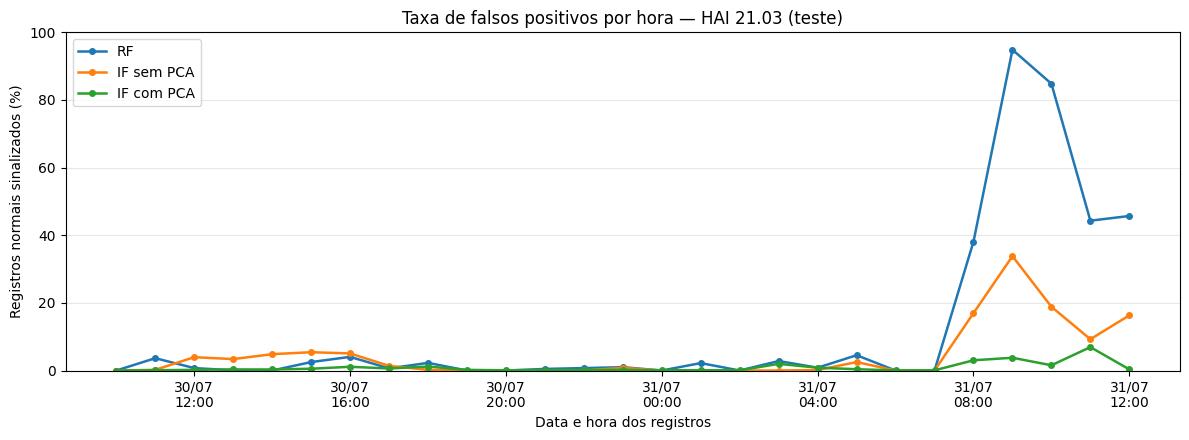

In [10]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

dados_grafico = resumo_fp_hora.sort_index()

fig, ax = plt.subplots(figsize=(12, 4.5))

for nome in sufixos:
    ax.plot(
        dados_grafico.index,
        dados_grafico[f"Taxa FP {nome} (%)"],
        marker="o",
        markersize=4,
        linewidth=1.8,
        label=nome
    )

ax.set_title(
    "Taxa de falsos positivos por hora — HAI 21.03 (teste)"
)
ax.set_xlabel("Data e hora dos registros")
ax.set_ylabel("Registros normais sinalizados (%)")
ax.set_ylim(0, 100)

ax.xaxis.set_major_locator(
    mdates.HourLocator(interval=4)
)
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d/%m\n%H:%M")
)

ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()

# Salvar versões para utilizar no trabalho.
fig.savefig(
    RESULTS_DIR / "teste_falsos_positivos_por_hora.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    RESULTS_DIR / "teste_falsos_positivos_por_hora.pdf",
    bbox_inches="tight"
)

plt.show()

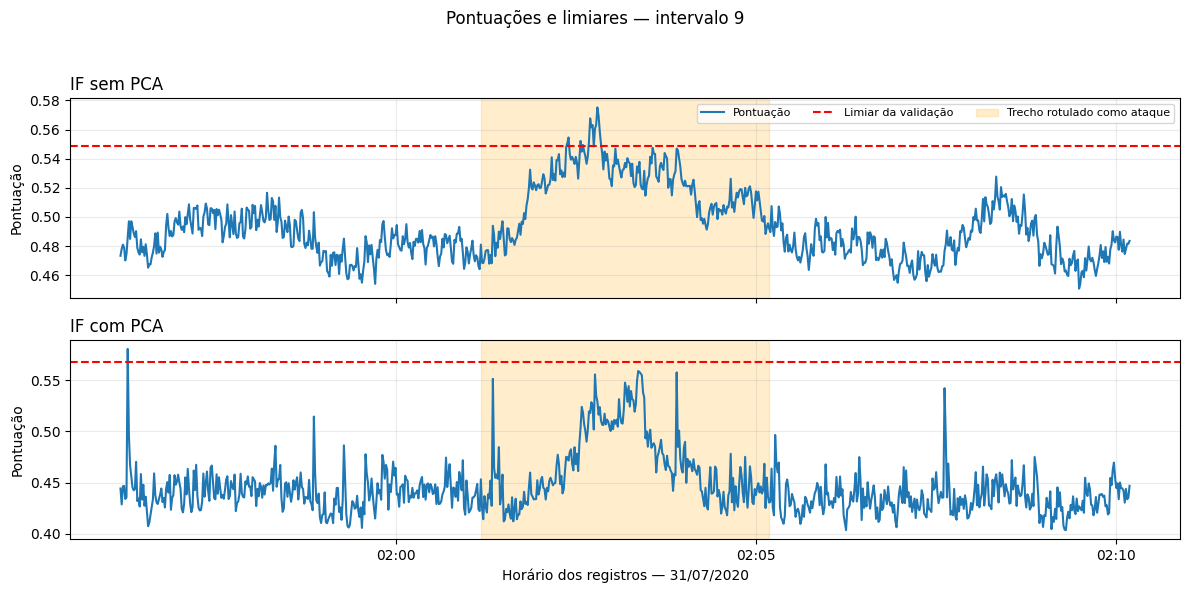

In [11]:
intervalo_id = 9

intervalo = (
    resumo_intervalos
    .set_index("intervalo_id")
    .loc[intervalo_id]
)

inicio = intervalo["inicio"]
fim = intervalo["fim"]
margem = pd.Timedelta(minutes=5)

trecho_grafico = resultados_teste.loc[
    resultados_teste["time"].between(
        inicio - margem,
        fim + margem
    )
].copy()

configuracoes = {
    "IF sem PCA": "if_sem_pca",
    "IF com PCA": "if_com_pca"
}

fig, eixos = plt.subplots(
    2, 1, figsize=(12, 6), sharex=True
)

for ax, (nome, sufixo) in zip(eixos, configuracoes.items()):
    ax.plot(
        trecho_grafico["time"],
        trecho_grafico[f"pontuacao_{sufixo}"],
        label="Pontuação"
    )

    ax.axhline(
        limiares_teste[nome],
        color="red",
        linestyle="--",
        label="Limiar da validação"
    )

    ax.axvspan(
        inicio,
        fim,
        color="orange",
        alpha=0.2,
        label="Trecho rotulado como ataque"
    )

    ax.set_title(nome, loc="left")
    ax.set_ylabel("Pontuação")
    ax.grid(alpha=0.25)

eixos[0].legend(fontsize=8, ncol=3)

eixos[-1].xaxis.set_major_formatter(
    mdates.DateFormatter("%H:%M")
)
eixos[-1].set_xlabel(
    f"Horário dos registros — {inicio:%d/%m/%Y}"
)

fig.suptitle(f"Pontuações e limiares — intervalo {intervalo_id}")
fig.tight_layout(rect=(0, 0, 1, 0.95))

for extensao in ["png", "pdf"]:
    fig.savefig(
        RESULTS_DIR / f"teste_intervalo_{intervalo_id}_if.{extensao}",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
exp.registrar("teste", registros=len(y_teste), intervalos=len(resumo_intervalos))
